In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

In [26]:
img = cv2.imread("chessboard.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)
img = cv2.resize(img, (224, 224))
# output_img = np.zeros_like(img, dtype=np.float32)
output_img = img.copy()

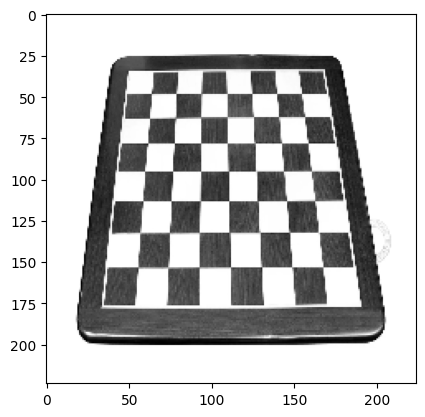

In [27]:
plt.imshow(img, cmap="gray")

In [28]:
img.shape

(224, 224)

In [31]:
circle16 = [
    (-3,  0),
    (-3,  1),
    (-2,  2),
    (-1,  3),
    ( 0,  3),
    ( 1,  3),
    ( 2,  2),
    ( 3,  1),
    ( 3,  0),
    ( 3, -1),
    ( 2, -2),
    ( 1, -3),
    ( 0, -3),
    (-1, -3),
    (-2, -2),
    (-3, -1),
]

threshold = 40

# check if n contiugous are all greater or lesser
def n_contiguous_check(arr, center_pixel_intensity, threshold, n=9):
    arr = arr + arr
    for i in range(len(arr)):
        if np.all(np.array(arr[i:i+n]) > center_pixel_intensity + threshold) or np.all(np.array(arr[i:i+n]) < center_pixel_intensity - threshold):
            return True
    return False


for i in range(3, img.shape[0] - 3):
    for j in range(3, img.shape[1] - 3):
        pixels = [int(img[i + di, j + dj]) for di, dj in circle16]
        if n_contiguous_check(pixels, img[i, j], threshold):
            output_img = cv2.circle(output_img, (j, i), 2, (0, 0, 0), 1)


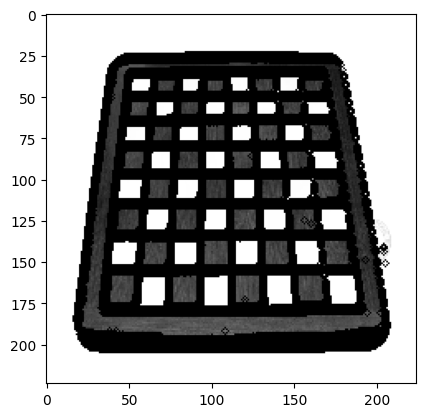

In [32]:
plt.imshow(output_img, cmap='grey')